# Final Project

## Part 0 Project Proposal
Before we do the project, you will need to create a repository
1. Create the project remotely on GitHub.  You will want to include a README
2. Install GitHub Desktop.
3. From the remote repo, clone down to your local and use github desktop to create it.
4. Copy the notebook into your local repo
5. Commit and push

***Invite me and the GA to your repo***

As you make changes locally, commit and push them. 

To complete the proposal. You will record the following in your README

1. The kind of data you want to find
2. The question/s you want to answer with the data.
3. URLs for the site/s that have the data you want.

***Note: You must aquire the data via an API or Web scraping.  Downloading a file will not get points.***

All code for your project will be recorded in this note book. Create extra code cells as needed.


# Part 1: Data aquisition
    1. Get raw data and put it into files. If needed, gather a representative amount of data.  Then append additional data as available.
    


In [14]:
# Part 1: Put code here
from api_key import API_KEY
import cfbd
import json

configuration = cfbd.Configuration()
configuration.access_token = API_KEY
api_client = cfbd.ApiClient(configuration)
stats_api = cfbd.StatsApi(api_client)
games_api = cfbd.GamesApi(api_client)
season_stats = stats_api.get_team_stats(year=2025)

with open('raw_season_stats.json', 'w') as f:
    json.dump([s.to_dict() for s in season_stats], f)
records = games_api.get_records(year=2025)

with open('raw_records.json', 'w') as f:
    json.dump([r.to_dict() for r in records], f)

## Part 2 Data processing

1. Process the raw data and store results in a file as needed.
2. Do analysis of the data
   

In [15]:
#Part 2: Put code here
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt

with open('raw_records.json', 'r') as f:
    records_data = json.load(f)

with open('raw_season_stats.json', 'r') as f:
    stats_data = json.load(f)

records_list = []
for r in records_data:
    if 'total' in r and isinstance(r['total'], dict):
        records_list.append({'team': r['team'], 'conference': r['conference'], 'wins': r['total']['wins']})

df_records = pd.DataFrame(records_list)
target_conferences = ['Big Ten', 'Big 12', 'SEC', 'ACC']
df_records = df_records[df_records['conference'].isin(target_conferences)]
df_stats_raw = pd.DataFrame(stats_data)
df_stats = df_stats_raw.pivot(index='team', columns='statName', values='statValue').reset_index()
df_merged = pd.merge(df_records, df_stats, on='team', how='inner')
df_merged['turnover_margin'] = df_merged['turnoversOpponent'] - df_merged['turnovers']
df_merged['net_yardage'] = df_merged['totalYards'] - df_merged['totalYardsOpponent']

df_merged.to_csv('power4_analysis_data.csv', index=False)
print("Analysis ready for", len(df_merged), "teams across the ACC, Big 12, Big Ten, and SEC.")

Analysis ready for 67 teams across the ACC, Big 12, Big Ten, and SEC.


To get the data needed, I had to pull offensive, defensive and season stats like record from the database so that I could analyze the teams based on their offense and defense to see if having a better offense gives you a better chance of winning, rather than having a better defense. Instead of doing every college football team, I decided to pull from the 4 major conferences in college football because they have the most stats and consistently play the same level of high competition and face each other often. This will make the data more usable because you can see a direct correlation between wins and offense or defensive stats, as well as net yards and wins. Meaning that you can effectively see if offense or defensive is more important when it comes to winning games.

## Part 3 Visualization

1. Create good graphs
2. Give narative conclusions explaining what is being demonstrated in the visualizations.

   

C:\Users\s560346\AppData\Local\Temp\ipykernel_3228\2214077905.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='conference', y='wins', palette='Set2')


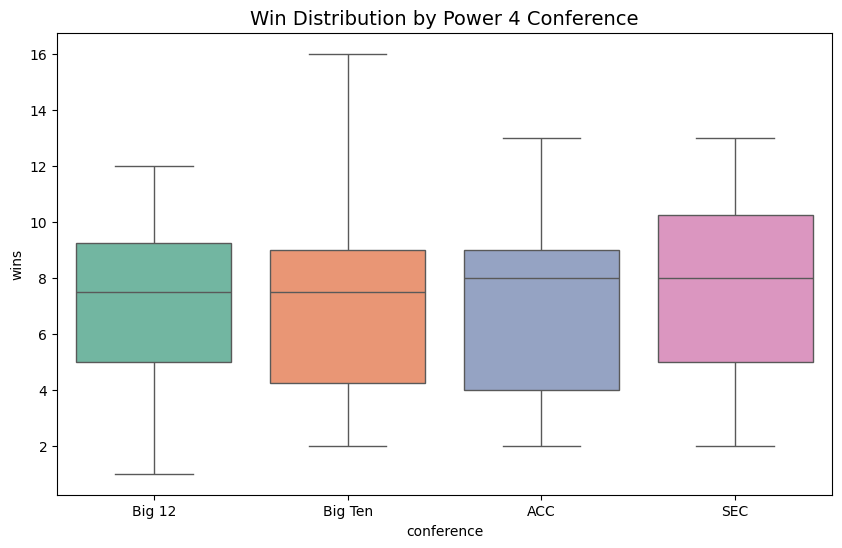

C:\Users\s560346\AppData\Local\Temp\ipykernel_3228\2214077905.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='conference', y='off_points_per_100yds', palette='Set2')


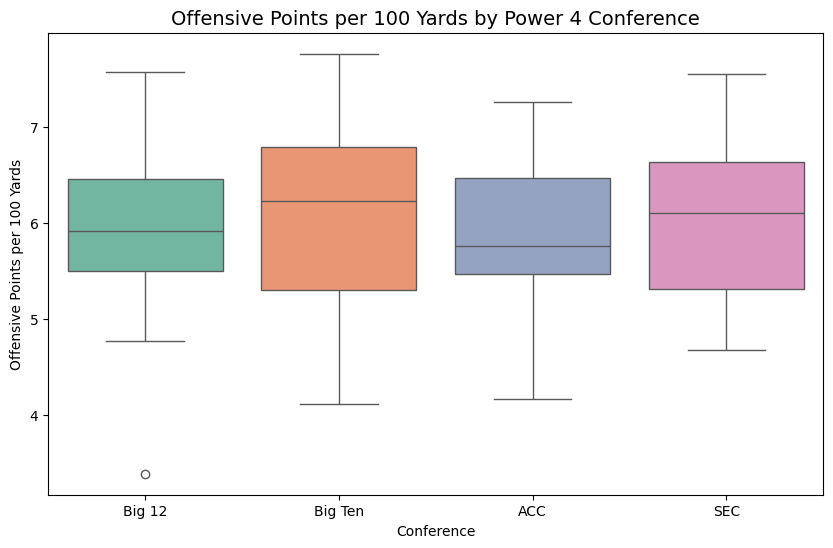

C:\Users\s560346\AppData\Local\Temp\ipykernel_3228\2214077905.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='conference', y='def_points_per_100yds', palette='Set2')


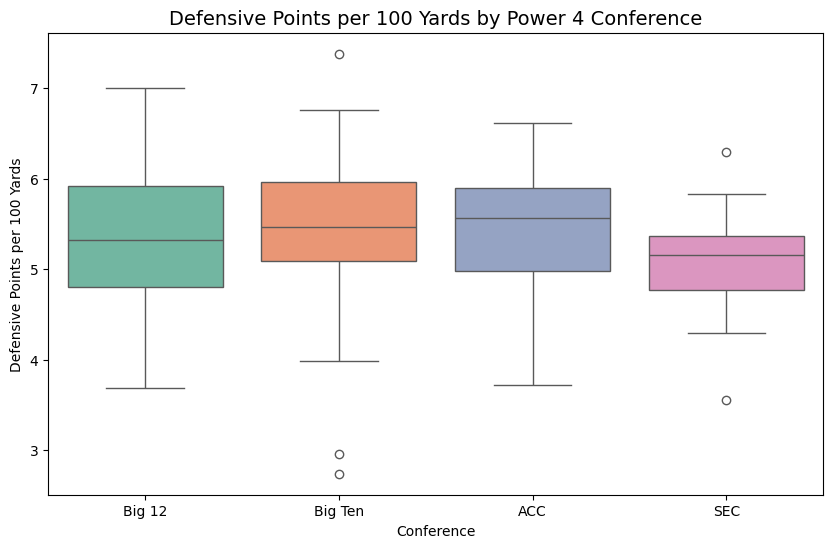

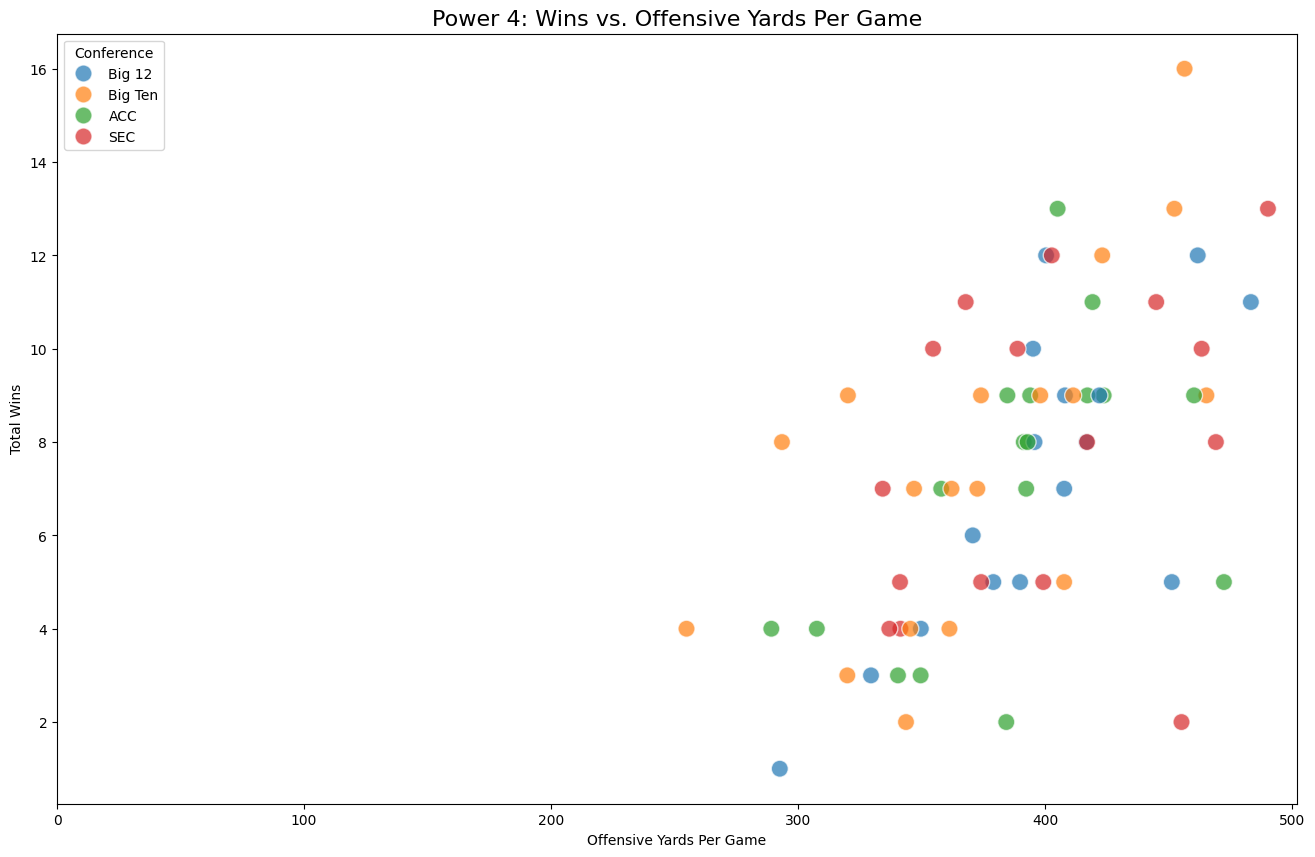

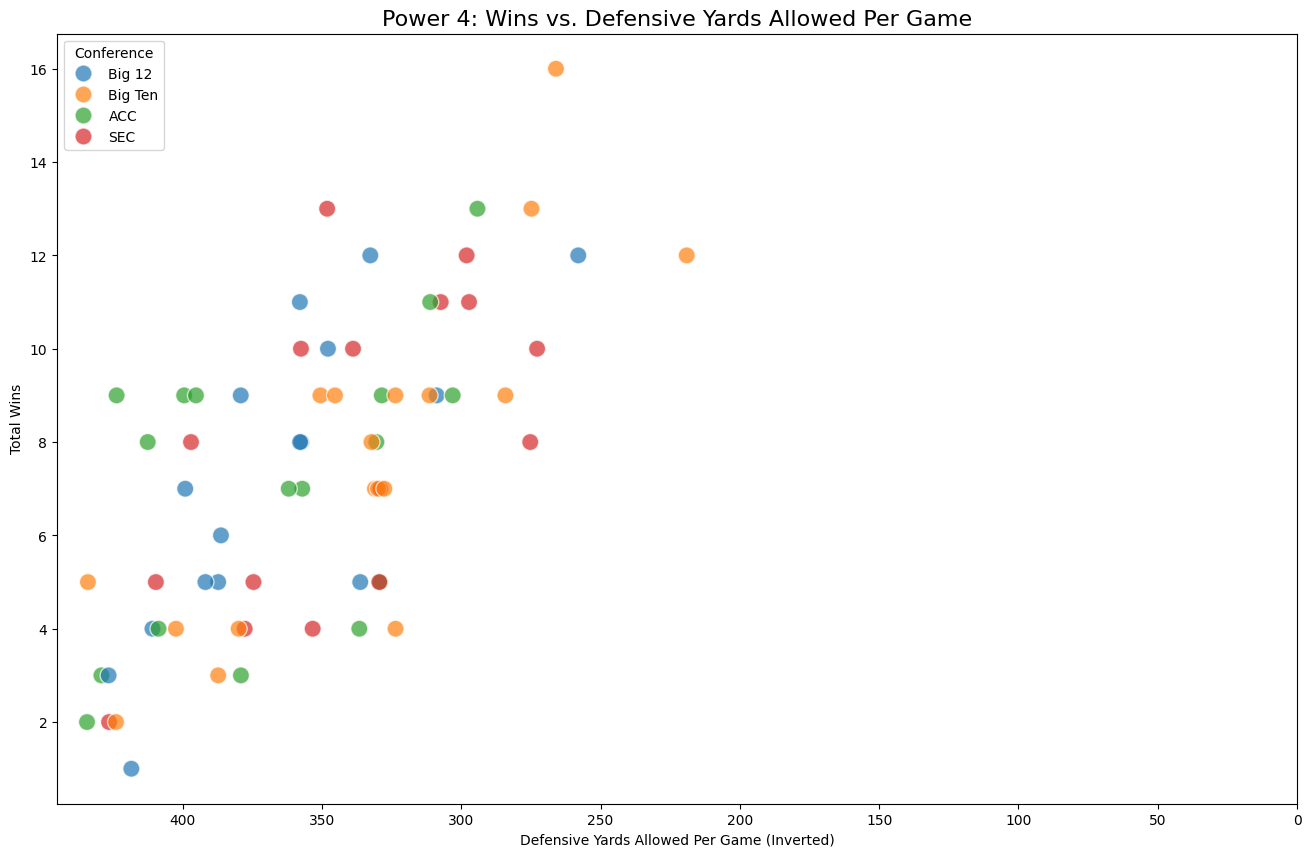

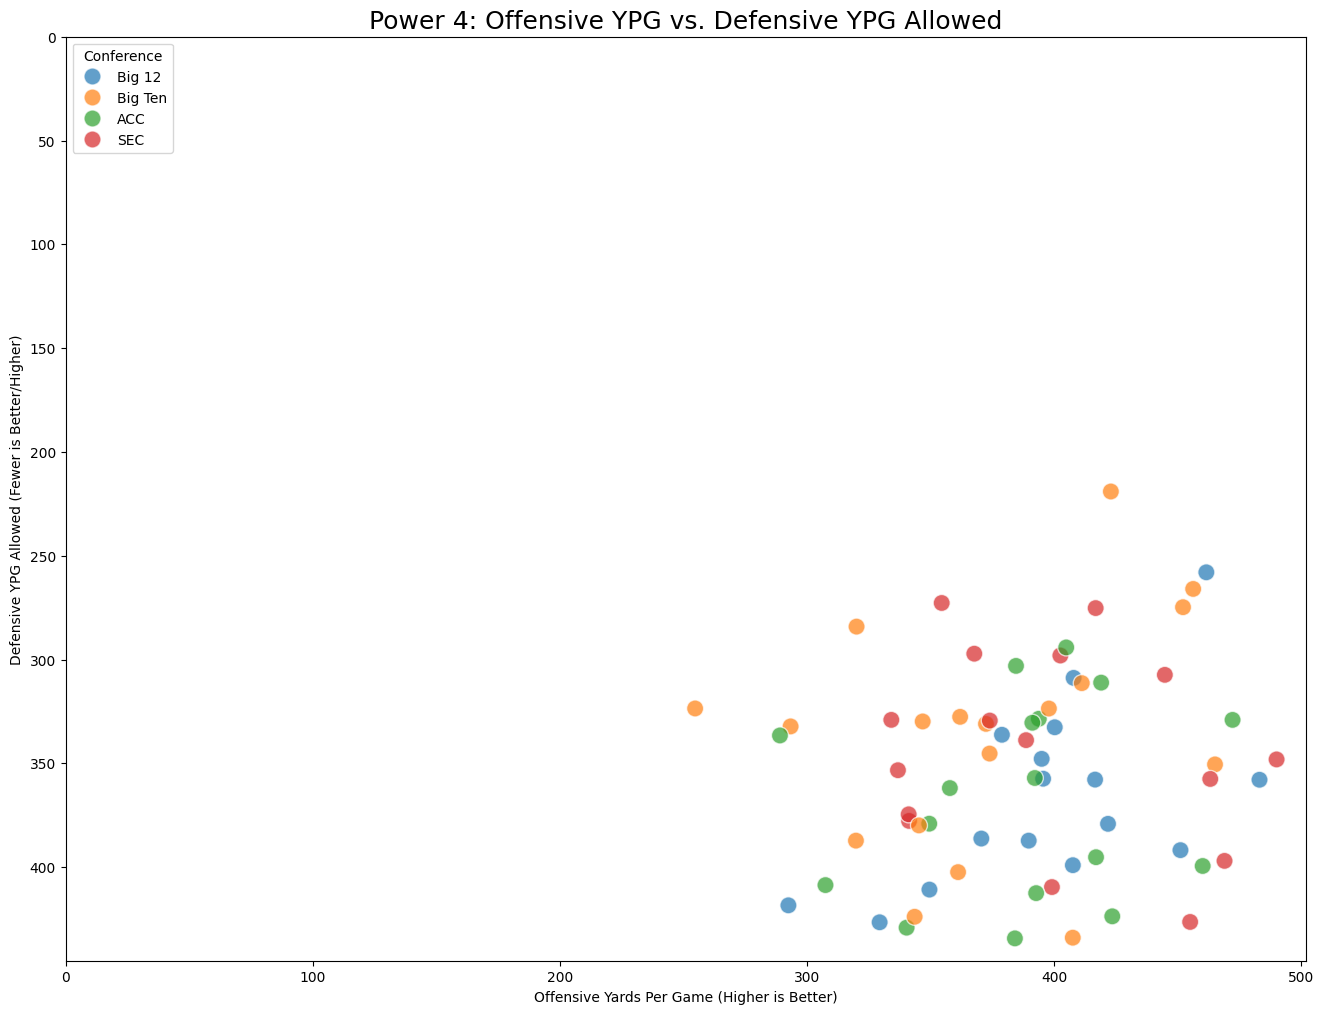

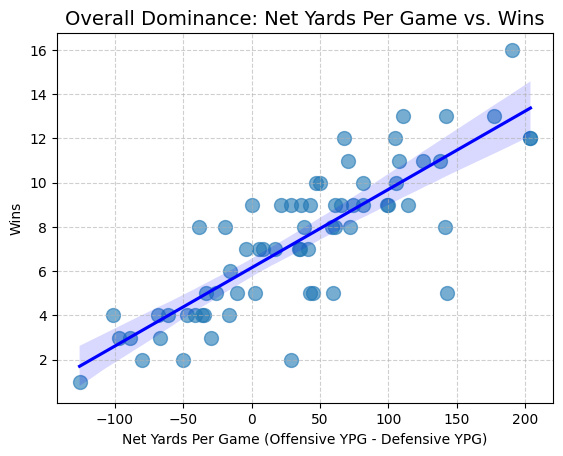

In [17]:
#Part 3: Put code here
df_merged['off_ypg'] = df_merged['totalYards'] / df_merged['games']
df_merged['def_ypg'] = df_merged['totalYardsOpponent'] / df_merged['games']
df_merged['net_ypg'] = (df_merged['totalYards'] - df_merged['totalYardsOpponent']) / df_merged['games']

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='conference', y='wins', palette='Set2')
plt.title('Win Distribution by Power 4 Conference', fontsize=14)
plt.show()

df_merged['estimated_points'] = (df_merged['passingTDs'] + df_merged['rushingTDs']) * 7
df_merged['off_points_per_100yds'] = (df_merged['estimated_points'] / df_merged['totalYards']) * 100

df_merged['estimated_points_allowed'] = (df_merged['passingTDsOpponent'] + df_merged['rushingTDsOpponent']) * 7
df_merged['def_points_per_100yds'] = (df_merged['estimated_points_allowed'] / df_merged['totalYardsOpponent']) * 100

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='conference', y='off_points_per_100yds', palette='Set2')
plt.title('Offensive Points per 100 Yards by Power 4 Conference', fontsize=14)
plt.xlabel('Conference')
plt.ylabel('Offensive Points per 100 Yards')
plt.savefig('off_points_per_100yds_by_conference.png', dpi=300)
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='conference', y='def_points_per_100yds', palette='Set2')
plt.title('Defensive Points per 100 Yards by Power 4 Conference', fontsize=14)
plt.xlabel('Conference')
plt.ylabel('Defensive Points per 100 Yards')
plt.savefig('def_points_per_100yds_by_conference.png', dpi=300)
plt.show()

plt.figure(figsize=(16, 10))
sns.scatterplot(data=df_merged, x='off_ypg', y='wins', hue='conference', s=150, alpha=0.7)
plt.xlim(left=0)
plt.title('Power 4: Wins vs. Offensive Yards Per Game', fontsize=16)
plt.xlabel('Offensive Yards Per Game')
plt.ylabel('Total Wins')
plt.legend(loc='upper left', title='Conference', fontsize=10)
plt.show()

plt.figure(figsize=(16, 10))
sns.scatterplot(data=df_merged, x='def_ypg', y='wins', hue='conference', s=150, alpha=0.7)
plt.gca().invert_xaxis()
plt.xlim(right=0) 
plt.title('Power 4: Wins vs. Defensive Yards Allowed Per Game', fontsize=16)
plt.xlabel('Defensive Yards Allowed Per Game (Inverted)')
plt.ylabel('Total Wins')
plt.legend(loc='upper left', title='Conference', fontsize=10)
plt.show()

plt.figure(figsize=(16, 12))
sns.scatterplot(data=df_merged, x='off_ypg', y='def_ypg', hue='conference', s=150, alpha=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.gca().invert_yaxis()
plt.title('Power 4: Offensive YPG vs. Defensive YPG Allowed', fontsize=18)
plt.xlabel('Offensive Yards Per Game (Higher is Better)')
plt.ylabel('Defensive YPG Allowed (Fewer is Better/Higher)')
plt.legend(loc='upper left', title='Conference', fontsize=10)
plt.show()

sns.regplot(data=df_merged, x='net_ypg', y='wins', scatter_kws={'s':100, 'alpha':0.6},  line_kws={"color": "blue"})
plt.title('Overall Dominance: Net Yards Per Game vs. Wins', fontsize=14)
plt.xlabel('Net Yards Per Game (Offensive YPG - Defensive YPG)')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Wins by conference: shows us that wins are fairly even compared to all of the conferences meaning that the data for all teams should be similar.

offensive points per 100 yards: tells us how efficient an offense is when moving the ball. This is very important because if a team cannot score efficiently, it will be much harder to win games.

defensive points per 100 yards: shows us how good the defense is at stopping teams from scoring. This is also extremely important because if your defense gives up a lot of points per 100 yards, you have to be very efficient on the offensive side of the ball in order to win games.

wins vs offensive yards per game: tells us how well the offense is able to move the ball but does not tell us efficiency.

wins vs defensive yards per game: tells us how good the defense is at getting off of the field but does not give us an idea about how many points they give up each game.

offense vs defense yards per game: Great visualization of how offenses are compared to their defense.

net yards per game: Gives us the best visualization showing how having more yards than giving up more yards is very important when it comes to winning games. teams above the line are closer to the line than some of the teams below the line. This could be because it is easier to get yards and not be efficient when it comes to scoring than it is to be efficient and move the ball less. If you aren't efficient, you have to gain significantly more yards in order to score more points than teams that are efficient with the ball, showing on the graph that being less efficient is easier to do and doesn't lead to more wins, telling us that efficiency is more important than total yards.

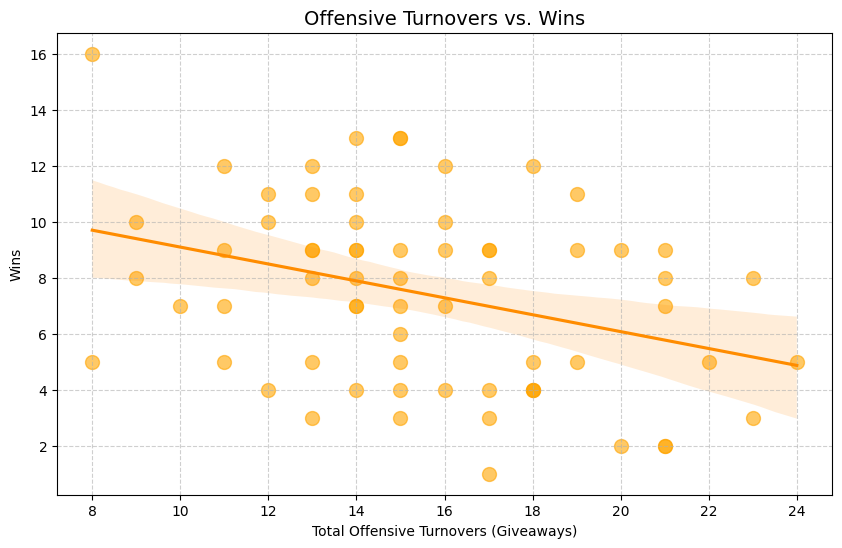

-0.3018546988976478


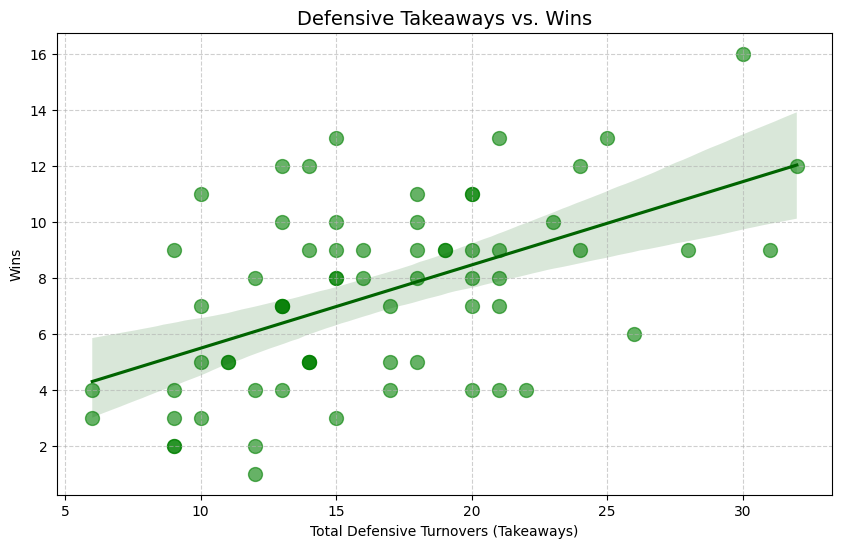

0.29731006761433204


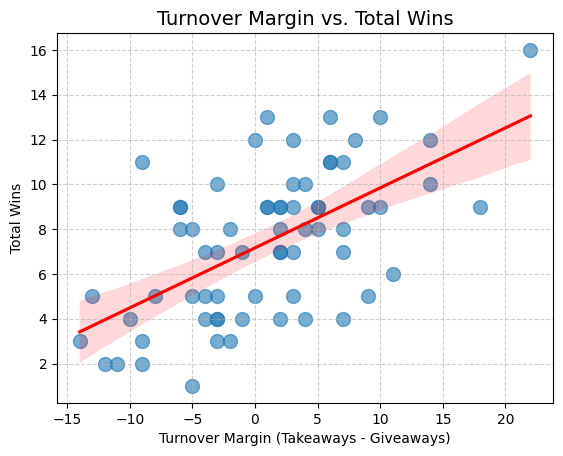

0.2679242880787675


In [18]:
#More calculations and graphs about turnovers and win
from scipy.stats import linregress

slope, intercept, r_value, p_value, std_err = linregress(df_merged['turnovers'], df_merged['wins'])

plt.figure(figsize=(10, 6))
sns.regplot(data=df_merged, x='turnovers', y='wins', scatter_kws={'s':100, 'alpha':0.6, 'color': 'orange'},  line_kws={"color": "darkorange"})
plt.title('Offensive Turnovers vs. Wins', fontsize=14)
plt.xlabel('Total Offensive Turnovers (Giveaways)')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
print(linregress(df_merged['turnovers'], df_merged['wins']).slope)

plt.figure(figsize=(10, 6))
sns.regplot(data=df_merged, x='turnoversOpponent', y='wins', scatter_kws={'s':100, 'alpha':0.6, 'color': 'green'}, line_kws={"color": "darkgreen"})
plt.title('Defensive Takeaways vs. Wins', fontsize=14)
plt.xlabel('Total Defensive Turnovers (Takeaways)')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
print(linregress(df_merged['turnoversOpponent'], df_merged['wins']).slope)

sns.regplot(data=df_merged, x='turnover_margin', y='wins', scatter_kws={'s':100, 'alpha':0.6}, line_kws={"color": "red"})
plt.title('Turnover Margin vs. Total Wins', fontsize=14)
plt.xlabel('Turnover Margin (Takeaways - Giveaways)')
plt.ylabel('Total Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
print(linregress(df_merged['turnover_margin'], df_merged['wins']).slope)

Graph 1: Offensive turnovers compared to wins: the line shows that the more turnovers you give up, the less games you win on average. However, the points are not overly close to the line, I think this is because it doesn't take defense into account which is a big factor when it comes to turning the ball over because if you turn the ball over but your defense stops them from scoring points, it won't hurt your team as much.
Graph 2: Defensive turnovers vs wins: The graph shows that the more turnovers you cause on the season, the more games you will win. But just like the first graph, it only takes a part of the game into consideration. It does show a stronger correlation than the offensive turnovers though.
Graph 3: This is the best graph between the 3 that have to do with turnovers because it brings both sides of the ball into account. By choosing net turnovers, you can see how important causing more turnovers are than giving up turnovers. The poins are closer to the line as well, but points are still somewhat far from the correlation line.